# 교통수단별 교통사고현황

In [ ]:
import pandas as pd

df = pd.read_excel('../data/교통수단별_교통사고현황.xlsx', header=None, sheet_name=0)
df.head()

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7,8,9,10
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,구분,도로,도로,철도,철도,지하철,지하철,해운,해운,항공,항공
3,구분,발생건수,사망자수,발생건수,사망자수,발생건수,사망자수,발생건수,사망자수,발생건수,사망자수
4,2024년,196349,2521,53,21,-,-,3255,164,22,182


In [3]:
# Extract third and fouth rows
header1 = df.iloc[2]
header2 = df.iloc[3]

# Combine headers
accidents_type_count = [
    f"{col1}_{col2}" if col1 != col2 else col1
    for col1, col2 in zip(header1, header2)
]

print(accidents_type_count)

['구분', '도로_발생건수', '도로_사망자수', '철도_발생건수', '철도_사망자수', '지하철_발생건수', '지하철_사망자수', '해운_발생건수', '해운_사망자수', '항공_발생건수', '항공_사망자수']


In [4]:
# Remove first four rows
df = df.iloc[4:].copy()

# Assign new column names
df.columns = accidents_type_count

# Reset index
df = df.reset_index(drop=True)

df.head()

,구분,도로_발생건수,도로_사망자수,철도_발생건수,철도_사망자수,지하철_발생건수,지하철_사망자수,해운_발생건수,해운_사망자수,항공_발생건수,항공_사망자수
0,2024년,196349,2521,53,21,-,-,3255,164,22,182
1,2023년,198296,2551,68,19,-,-,3092,94,18,8
2,2022년,196836,2735,82,28,-,-,2863,99,25,17
3,2021년,203130,2916,64,21,-,-,2720,120,13,8
4,2020년,209654,3081,58,22,-,-,3156,126,14,8


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   구분        46 non-null     object
 1   도로_발생건수   45 non-null     object
 2   도로_사망자수   45 non-null     object
 3   철도_발생건수   45 non-null     object
 4   철도_사망자수   45 non-null     object
 5   지하철_발생건수  45 non-null     object
 6   지하철_사망자수  45 non-null     object
 7   해운_발생건수   45 non-null     object
 8   해운_사망자수   45 non-null     object
 9   항공_발생건수   45 non-null     object
 10  항공_사망자수   45 non-null     object
dtypes: object(11)
memory usage: 4.2+ KB


In [6]:
df.shape

(47, 11)

In [7]:
df.tail(5)

,구분,도로_발생건수,도로_사망자수,철도_발생건수,철도_사망자수,지하철_발생건수,지하철_사망자수,해운_발생건수,해운_사망자수,항공_발생건수,항공_사망자수
42,1982년,141128,6110,1849,755,8,4,301,42,-,-
43,1981년,123373,5804,1894,858,15,7,336,123,2,-
44,1980년,120182,5608,2136,778,7,4,255,147,4,17
45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,주) 항공 : 2012년부터 항공기ㆍ경량항공기ㆍ초경량비행장치 사고를 포함\n(국내·...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
## drop some necessary rows.
df = df.iloc[:-2].copy()
df.tail(5)

,구분,도로_발생건수,도로_사망자수,철도_발생건수,철도_사망자수,지하철_발생건수,지하철_사망자수,해운_발생건수,해운_사망자수,항공_발생건수,항공_사망자수
40,1984년,134335,7468,1816,755,13,9,486,143,1,5
41,1983년,170026,6834,1932,714,9,5,300,74,5,276
42,1982년,141128,6110,1849,755,8,4,301,42,-,-
43,1981년,123373,5804,1894,858,15,7,336,123,2,-
44,1980년,120182,5608,2136,778,7,4,255,147,4,17


In [9]:
df.shape

(45, 11)

In [10]:
print(df.iloc[0])

구분           2024년
도로_발생건수     196349
도로_사망자수       2521
철도_발생건수         53
철도_사망자수         21
지하철_발생건수         -
지하철_사망자수         -
해운_발생건수       3255
해운_사망자수        164
항공_발생건수         22
항공_사망자수        182
Name: 0, dtype: object


In [11]:
import numpy as np

df = df.replace('-', np.nan)

/var/folders/lv/pm52mzvx1_5532wy9gbjfh0c0000gn/T/ipykernel_20466/3316565946.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('-', np.nan)


In [12]:
# Check for missing values
df.isnull().sum()

구분           0
도로_발생건수      0
도로_사망자수      0
철도_발생건수      0
철도_사망자수      0
지하철_발생건수    14
지하철_사망자수    14
해운_발생건수      0
해운_사망자수      0
항공_발생건수      1
항공_사망자수      7
dtype: int64

In [13]:
# Rename the year column
df = df.rename(columns={'구분': '연도'})

# Change year to integer type for time-series visualization
df['연도'] = (
    df['연도'].astype(str)
    .str.extract(r'(\d{4})')
    .astype(int)
)

print(df.head(10))

     연도  도로_발생건수  도로_사망자수  철도_발생건수  철도_사망자수  지하철_발생건수  지하철_사망자수  해운_발생건수  \
0  2024   196349     2521       53       21       NaN       NaN     3255   
1  2023   198296     2551       68       19       NaN       NaN     3092   
2  2022   196836     2735       82       28       NaN       NaN     2863   
3  2021   203130     2916       64       21       NaN       NaN     2720   
4  2020   209654     3081       58       22       NaN       NaN     3156   
5  2019   229600     3349       72       33       NaN       NaN     2971   
6  2018   217148     3781       97       44       NaN       NaN     2671   
7  2017   216335     4185      105       51       NaN       NaN     2582   
8  2016   220917     4292      124       62       NaN       NaN     2307   
9  2015   232035     4621      138       76       NaN       NaN     2101   

   해운_사망자수  항공_발생건수  항공_사망자수  
0      164     22.0    182.0  
1       94     18.0      8.0  
2       99     25.0     17.0  
3      120     13.0      8.0  
4      1

In [14]:
# Convert numerical columns
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Sort by year (oldest to newest)
df = df.sort_values('연도').reset_index(drop=True)

# Check data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   연도        45 non-null     int64  
 1   도로_발생건수   45 non-null     int64  
 2   도로_사망자수   45 non-null     int64  
 3   철도_발생건수   45 non-null     int64  
 4   철도_사망자수   45 non-null     int64  
 5   지하철_발생건수  31 non-null     float64
 6   지하철_사망자수  31 non-null     float64
 7   해운_발생건수   45 non-null     int64  
 8   해운_사망자수   45 non-null     int64  
 9   항공_발생건수   44 non-null     float64
 10  항공_사망자수   38 non-null     float64
dtypes: float64(4), int64(7)
memory usage: 4.0 KB


In [15]:
df.head(10)

,연도,도로_발생건수,도로_사망자수,철도_발생건수,철도_사망자수,지하철_발생건수,지하철_사망자수,해운_발생건수,해운_사망자수,항공_발생건수,항공_사망자수
0,1980,120182,5608,2136,778,7.0,4.0,255,147,4.0,17.0
1,1981,123373,5804,1894,858,15.0,7.0,336,123,2.0,NaN
2,1982,141128,6110,1849,755,8.0,4.0,301,42,NaN,NaN
3,1983,170026,6834,1932,714,9.0,5.0,300,74,5.0,276.0
4,1984,134335,7468,1816,755,13.0,9.0,486,143,1.0,5.0
5,1985,146836,7522,1811,738,12.0,3.0,408,242,1.0,2.0
6,1986,153777,7702,1845,689,17.0,12.0,429,175,1.0,3.0
7,1987,175661,7206,1739,717,31.0,9.0,533,477,1.0,115.0
8,1988,225062,11563,1847,697,62.0,15.0,438,309,2.0,3.0
9,1989,255787,12603,1812,693,34.0,11.0,479,194,3.0,94.0


In [16]:
df.describe()

,연도,도로_발생건수,도로_사망자수,철도_발생건수,철도_사망자수,지하철_발생건수,지하철_사망자수,해운_발생건수,해운_사망자수,항공_발생건수,항공_사망자수
count,45.000000,45.000000,45.000000,45.000000,45.000000,31.000000,31.000000,45.000000,45.000000,44.000000,38.000000
mean,2002.000000,217559.955556,7093.577778,873.888889,337.577778,40.903226,29.419355,1188.888889,170.533333,6.409091,30.578947
std,13.133926,40874.883831,3055.297080,725.080285,271.315104,27.642184,44.990943,946.267962,90.829911,5.903559,65.119695
min,1980.000000,120182.000000,2521.000000,53.000000,19.000000,7.000000,3.000000,255.000000,42.000000,0.000000,0.000000
25%,1991.000000,203130.000000,5092.000000,232.000000,96.000000,17.500000,10.000000,529.000000,120.000000,2.750000,2.000000
50%,2002.000000,221711.000000,6376.000000,599.000000,252.000000,33.000000,17.000000,699.000000,148.000000,4.500000,6.000000
75%,2013.000000,246452.000000,9353.000000,1707.000000,588.000000,60.000000,35.500000,1809.000000,186.000000,9.500000,12.000000
max,2024.000000,290481.000000,13429.000000,2136.000000,858.000000,103.000000,256.000000,3255.000000,477.000000,25.000000,276.000000


In [17]:
df.isnull().sum()

연도           0
도로_발생건수      0
도로_사망자수      0
철도_발생건수      0
철도_사망자수      0
지하철_발생건수    14
지하철_사망자수    14
해운_발생건수      0
해운_사망자수      0
항공_발생건수      1
항공_사망자수      7
dtype: int64

In [18]:
df.iloc[:, 1::2].sum()

도로_발생건수     9790198.0
철도_발생건수       39325.0
지하철_발생건수       1268.0
해운_발생건수       53500.0
항공_발생건수         282.0
dtype: float64

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [20]:
# fig, ax = plt.subplots()

# sns.lineplot(data=df, x='연도', y='도로_발생건수', ax=ax)

# ax.set_title('연도별 도로 교통사고 발생건수')
# ax.set_xlabel('연도')
# ax.set_ylabel('발생건수')

# plt.show()

In [21]:
# fig, ax = plt.subplots()

# sns.lineplot(data=df, x='연도', y='도로_사망자수', ax=ax)

# ax.set_title('연도별 도로 교통사고 사망자수')
# ax.set_xlabel('연도')
# ax.set_ylabel('사망자수')

# plt.show()

## 연도별 도로 교통사고 발생건수 및 사망자수 Combined Line Plot

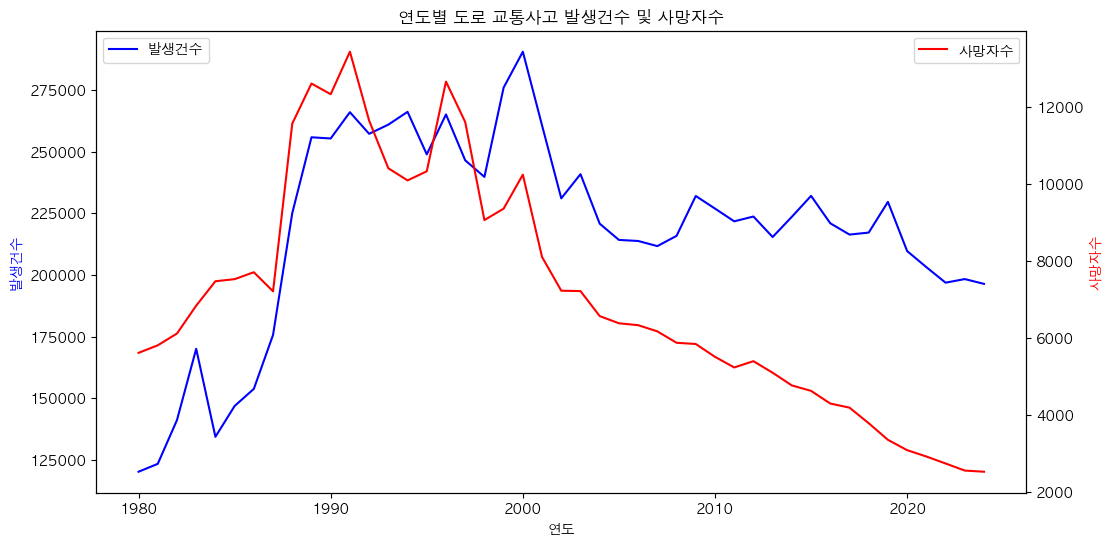

In [22]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax2 = ax1.twinx()

sns.lineplot(data=df, x='연도', y='도로_발생건수',
             color='blue', ax=ax1, legend=False)

sns.lineplot(data=df, x='연도', y='도로_사망자수',
             color='red', ax=ax2, legend=False)

ax1.set_title('연도별 도로 교통사고 발생건수 및 사망자수')
ax1.set_xlabel('연도')
ax1.set_ylabel('발생건수', color='blue')
ax2.set_ylabel('사망자수', color='red')

ax1.legend(['발생건수'], loc='upper left')
ax2.legend(['사망자수'], loc='upper right')

plt.show()

## 교통수단별 교통사고 발생건수 비교 Bar Plot

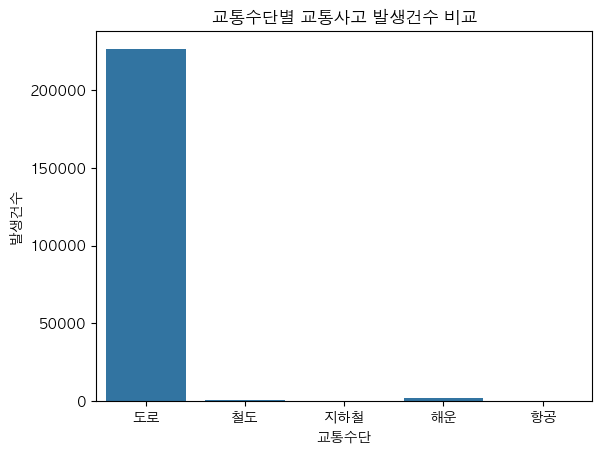

In [23]:
cols = ['도로_발생건수', '철도_발생건수',
        '지하철_발생건수', '해운_발생건수',
        '항공_발생건수']

data = df.dropna(subset=cols).iloc[-1]

fig, ax = plt.subplots()

sns.barplot(x=['도로', '철도', '지하철', '해운', '항공'],
            y=data[cols].values, ax=ax)

ax.set_title('교통수단별 교통사고 발생건수 비교')
ax.set_xlabel('교통수단')
ax.set_ylabel('발생건수')

plt.show()

## 교통사고 발생건수와 사망자수의 관계 Scatter Plot

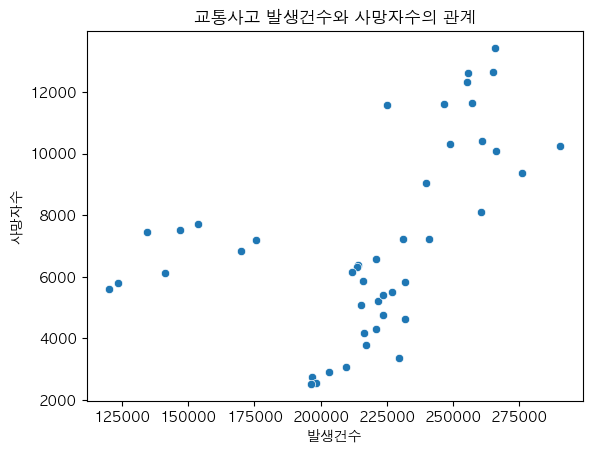

In [24]:
fig, ax = plt.subplots()

sns.scatterplot(data=df, x='도로_발생건수',
                y='도로_사망자수', ax=ax)

ax.set_title('교통사고 발생건수와 사망자수의 관계')
ax.set_xlabel('발생건수')
ax.set_ylabel('사망자수')

plt.show()

## 도로 교통사고 발생건수 분포 Histogram

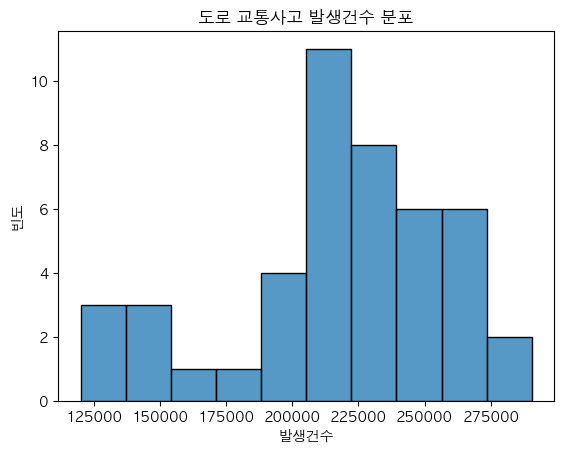

In [25]:
fig, ax = plt.subplots()

sns.histplot(data=df, x='도로_발생건수', bins=10, ax=ax)

ax.set_title('도로 교통사고 발생건수 분포')
ax.set_xlabel('발생건수')
ax.set_ylabel('빈도')

plt.show()